# Week 3: NumPy arrays, vectorization, and plotting

[Open in Colab](https://colab.research.google.com/github/WSU-EconS431/site/blob/main/weeks/week03.ipynb) · [View on GitHub](https://github.com/WSU-EconS431/site/blob/main/weeks/week03.ipynb)

Last week every calculation happened one number at a time inside a loop. Economic models usually need the same calculation at thousands of prices, quantities, or parameter values. **NumPy** arrays do that in one line, much faster, in code that reads like the algebra. **Matplotlib** then turns the results into figures.

**After this week you can:**

- create arrays and pick out parts of them by position or by condition
- apply a calculation to a whole array at once (vectorization) and explain why it is faster than a loop
- use summaries (`sum`, `argmax`, `argmin`) to search a grid for an optimum or an equilibrium
- build a market demand curve from many individual buyers
- make a labeled figure with several lines, a marked point, and a shaded area

Throughout, the market is $Q_d = a - bP$ and $Q_s = c + dP$ with $a = 90$, $b = 1.5$, $c = 0$, $d = 3$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

a, b, c, d = 90, 1.5, 0, 3

## 1. Why arrays?

Python lists are general containers, not vectors. Arithmetic on a list either repeats it or fails (the second cell fails on purpose; if Run All stops there, keep going a cell at a time):

In [2]:
prices = [10, 20, 30]
print(prices * 2)        # repeats the list; doesn't double the prices

[10, 20, 30, 10, 20, 30]


In [3]:
#| error: true
a - b * prices

TypeError: can't multiply sequence by non-int of type 'float'

A NumPy **array** holds numbers of one type, and arithmetic applies to every element. That's **vectorization**: you write the operation once, as you would on paper.

In [4]:
p = np.array([10, 20, 30])
print(p * 2)
print(a - b * p)

[20 40 60]
[75. 60. 45.]


## 2. Making arrays

| Function | Gives | Example |
|---|---|---|
| `np.array(list)` | an array from values you list | `np.array([1, 2, 3])` |
| `np.linspace(start, stop, n)` | `n` evenly spaced values, **including** `stop` | price grids |
| `np.arange(start, stop, step)` | values spaced by `step`, **excluding** `stop` | like `range` |
| `np.zeros(n)`, `np.ones(n)` | arrays to fill in later | |

In [5]:
grid = np.linspace(0, 60, 13)
print(grid)
print(np.arange(0, 60, 5))
print(grid.shape, grid.size, grid.dtype)

[ 0.  5. 10. 15. 20. 25. 30. 35. 40. 45. 50. 55. 60.]
[ 0  5 10 15 20 25 30 35 40 45 50 55]
(13,) 13 float64


## 3. Indexing, slicing, and Boolean masks

Positions work as in lists, starting at 0. A **slice** `start:stop:step` takes a range of positions (again excluding `stop`).

In [6]:
print(grid[0], grid[-1])   # first and last
print(grid[2:5])           # positions 2, 3, 4
print(grid[::3])           # every third element

0.0 60.0
[10. 15. 20.]
[ 0. 15. 30. 45. 60.]


Comparing an array to a number gives an array of `True`/`False` values, called a **Boolean mask**. Using a mask as an index keeps the elements where it is `True`. This is how you ask questions of a whole grid at once:

In [7]:
qd = a - b * grid
qs = c + d * grid
excess = qd - qs

shortage = excess > 0
print(shortage)
print("Prices with a shortage:", grid[shortage])
print("How many:", shortage.sum())        # True counts as 1, False as 0

[ True  True  True  True False False False False False False False False
 False]
Prices with a shortage: [ 0.  5. 10. 15.]
How many: 4


`np.where(condition, x, y)` picks `x` where the condition holds and `y` elsewhere:

In [8]:
np.where(excess > 0, "shortage", np.where(excess < 0, "surplus", "equilibrium"))

array(['shortage', 'shortage', 'shortage', 'shortage', 'equilibrium',
       'surplus', 'surplus', 'surplus', 'surplus', 'surplus', 'surplus',
       'surplus', 'surplus'], dtype='<U11')

## 4. Functions that work on arrays

A function built from arithmetic works on arrays with no changes. This is the Week 2 style of function, now applied to a whole grid:

In [9]:
def demand(p, a, b):
    """Quantity demanded at price p (a number or an array)."""
    return a - b * p

demand(np.array([0, 30, 60, 75]), a, b)

array([ 90. ,  45. ,   0. , -22.5])

Look at the last value: $P = 75$ is above the choke price $a/b = 60$, and linear demand turns negative there. A Week 2 `if` can't fix that for arrays, because `if` needs one `True` or `False`, and a comparison on an array gives many:

In [10]:
#| error: true
def demand_nonneg_loop_style(p, a, b):
    if p > a / b:
        return 0
    return a - b * p

demand_nonneg_loop_style(grid, a, b)

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

Use the vectorized tools instead. `np.maximum(x, 0)` compares element by element and replaces negatives with 0:

In [11]:
def demand_nonneg(p, a, b):
    """Quantity demanded, never below zero. Works for numbers and arrays."""
    return np.maximum(a - b * p, 0)

demand_nonneg(np.array([0, 30, 60, 75]), a, b)

array([90., 45.,  0.,  0.])

## 5. How much faster?

Vectorized code runs as compiled loops inside NumPy instead of one Python step at a time. Compare total revenue over a million prices:

In [12]:
import time

p_big = np.linspace(0, 60, 1_000_000)

t0 = time.perf_counter()
total = 0.0
for p_i in p_big:
    total += p_i * (a - b * p_i)
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
total_vec = np.sum(p_big * (a - b * p_big))
t_vec = time.perf_counter() - t0

print(f"loop:       {t_loop:.3f} s")
print(f"vectorized: {t_vec:.4f} s  ({t_loop / t_vec:.0f}x faster)")
print("same answer:", np.isclose(total, total_vec))

loop:       0.448 s
vectorized: 0.0119 s  (38x faster)
same answer: True


Speed matters once you simulate many agents or solve a model thousands of times (Weeks 8 and 15). Until then, the bigger gain is that the vectorized line is shorter and matches the math.

## 6. Searching a grid

Summaries collapse an array to one number: `np.sum`, `np.mean`, `np.max`, `np.min`. The `arg` versions, `np.argmax` and `np.argmin`, give the **position** of the largest or smallest element, which you then use to look up the price.

**Revenue-maximizing price.** Last week this took a loop and an `if`. Now:

In [13]:
p_fine = np.linspace(0, 60, 6001)              # steps of 0.01
rev = p_fine * demand(p_fine, a, b)
i = np.argmax(rev)
print(f"best price {p_fine[i]:.2f}, revenue {rev[i]:.2f}   (calculus: a/(2b) = {a / (2 * b):.2f})")

best price 30.00, revenue 1350.00   (calculus: a/(2b) = 30.00)


**Equilibrium on a grid.** The equilibrium is where excess demand is closest to zero:

In [14]:
ed = demand(p_fine, a, b) - (c + d * p_fine)
j = np.argmin(np.abs(ed))
p_star, q_star = p_fine[j], demand(p_fine[j], a, b)
print(f"grid: P* = {p_star:.2f}, Q* = {q_star:.2f}   formula: P* = {(a - c) / (b + d):.2f}")

grid: P* = 20.00, Q* = 60.00   formula: P* = 20.00


The equilibrium price (20) is not the revenue-maximizing price (30). A competitive market doesn't maximize sellers' revenue; no single seller controls the price. Week 11 returns to this with monopoly.

A grid answer is only as precise as the grid's step. Bisection (Week 2) and SciPy's solvers (Week 6) home in on the exact value instead.

**Comparative statics without a loop.** Week 1 looped over demand intercepts. Arrays do the whole set at once:

In [15]:
a_values = np.arange(60, 121, 10)
p_stars = (a_values - c) / (b + d)
q_stars = a_values - b * p_stars
print(np.column_stack([a_values, p_stars, q_stars]))

[[ 60.          13.33333333  40.        ]
 [ 70.          15.55555556  46.66666667]
 [ 80.          17.77777778  53.33333333]
 [ 90.          20.          60.        ]
 [100.          22.22222222  66.66666667]
 [110.          24.44444444  73.33333333]
 [120.          26.66666667  80.        ]]


## 7. Plotting with Matplotlib

Every figure in this course starts the same way: `fig, ax = plt.subplots()` creates a figure and a set of axes, and you draw on `ax`. Economists put price on the vertical axis, so quantity goes first in `ax.plot(x, y)`.

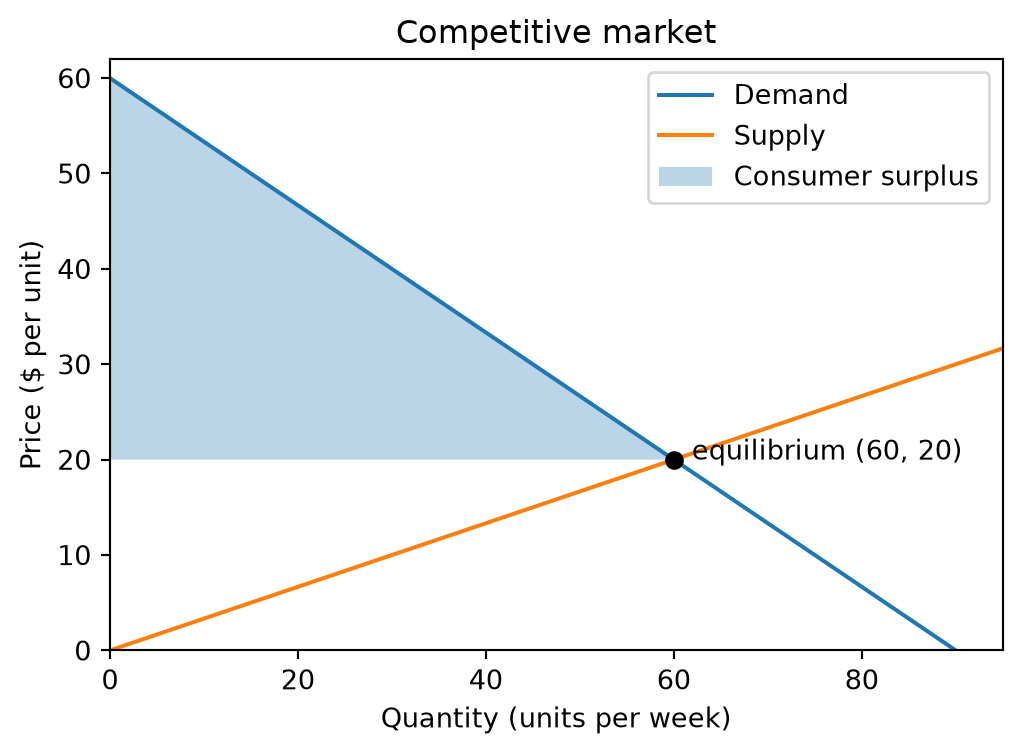

In [16]:
p_plot = np.linspace(0, 60, 200)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(demand(p_plot, a, b), p_plot, label="Demand")
ax.plot(c + d * p_plot, p_plot, label="Supply")
ax.plot(q_star, p_star, "o", color="black")
ax.annotate(f"  equilibrium ({q_star:.0f}, {p_star:.0f})", (q_star, p_star))

# Shade consumer surplus: between the demand curve and P*, from Q = 0 to Q*
q_cs = np.linspace(0, q_star, 100)
ax.fill_between(q_cs, (a - q_cs) / b, p_star, alpha=0.3, label="Consumer surplus")

ax.set_xlabel("Quantity (units per week)")
ax.set_ylabel("Price ($ per unit)")
ax.set_title("Competitive market")
ax.set_xlim(0, 95)
ax.set_ylim(0, 62)
ax.legend()
plt.show()

The shading uses **inverse demand**, $P = (a - Q)/b$, because the vertical axis is price.

**Several panels.** `plt.subplots(1, 2)` returns two axes side by side:

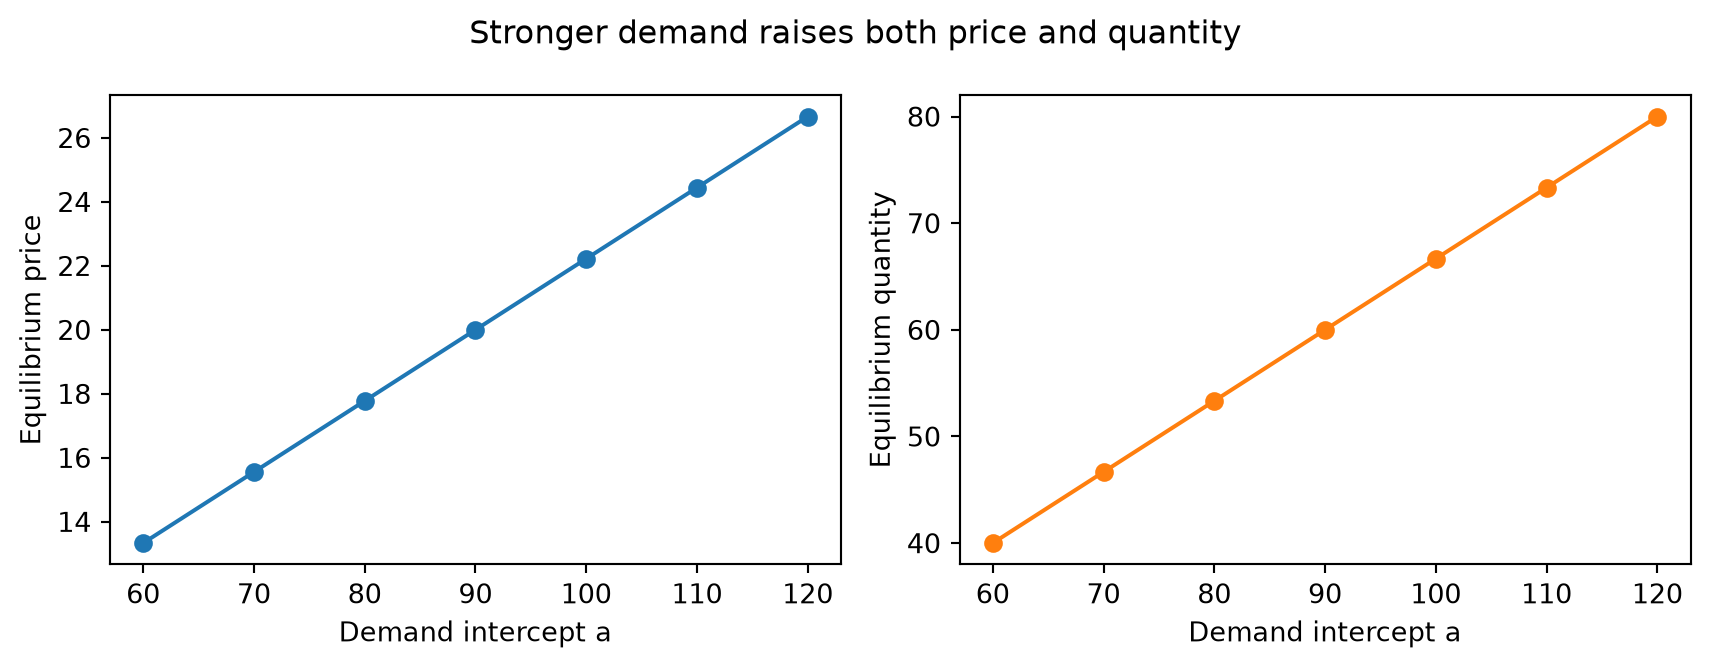

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.5))
ax1.plot(a_values, p_stars, "o-")
ax1.set_xlabel("Demand intercept a")
ax1.set_ylabel("Equilibrium price")
ax2.plot(a_values, q_stars, "o-", color="tab:orange")
ax2.set_xlabel("Demand intercept a")
ax2.set_ylabel("Equilibrium quantity")
fig.suptitle("Stronger demand raises both price and quantity")
fig.tight_layout()
plt.show()

To save a figure next to your notebook for a report or slide, add `fig.savefig("market.png", dpi=150, bbox_inches="tight")` before `plt.show()`.

**Checklist for a figure someone else will read**

- Axis labels say what is measured, with units.
- A legend whenever there is more than one line.
- The title states the takeaway, not just the variables.
- Axis ranges show the interesting part; don't let a negative quantity stretch the plot.
- Matplotlib's default colors are colorblind-safe. If you choose your own, check them.

## 8. Market demand from individual buyers

Where does a smooth demand curve come from? Suppose 90 buyers each want one unit and each has a **willingness to pay** (WTP). At price $P$, quantity demanded is the number of buyers whose WTP is at least $P$.

We draw WTPs at random from a uniform distribution between 0 and 60. The **seed** makes the "random" draws the same every time the notebook runs, so your results can be reproduced.

In [18]:
rng = np.random.default_rng(seed=431)
wtp = rng.uniform(0, 60, size=90)
print(np.round(np.sort(wtp)[:8], 1), "...")

print("Demand at P = 30:", (wtp >= 30).sum())

[0.8 1.2 1.3 1.7 2.  2.1 3.5 4.6] ...
Demand at P = 30: 49


For a whole price grid, compare every buyer with every price. `wtp[:, None]` turns the 90 WTPs into a column, so comparing it with the row of prices gives a 90 × 200 table of `True`/`False` values (this is called **broadcasting**). Summing down each column counts the buyers at each price.

(90, 200)


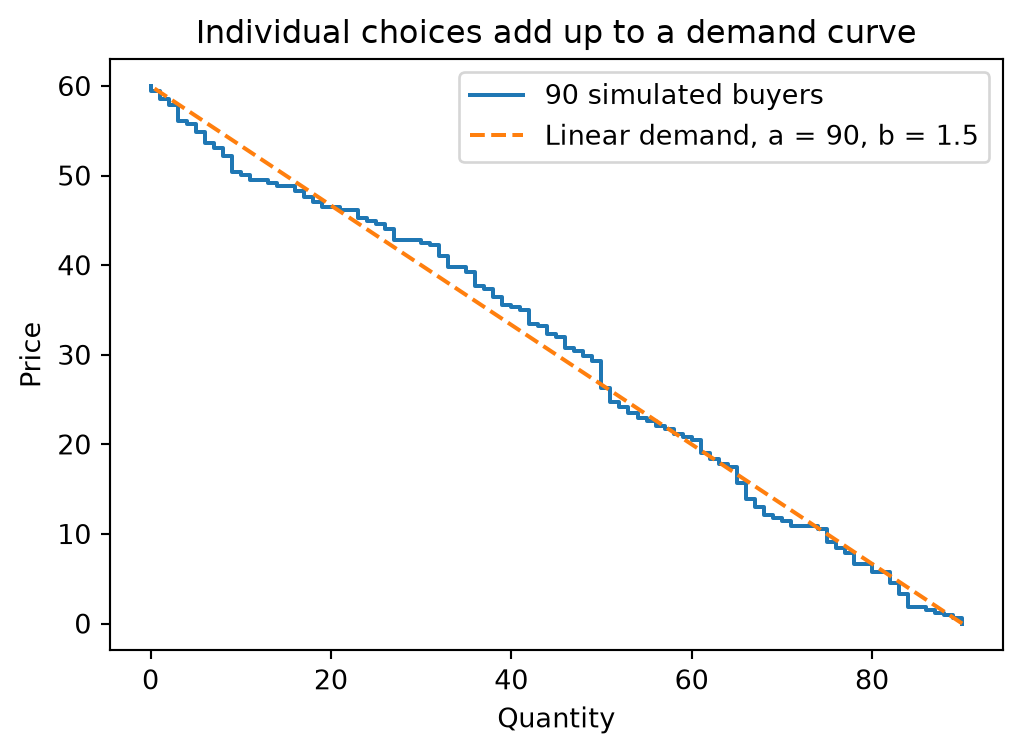

In [19]:
buys = wtp[:, None] >= p_plot     # shape (90 buyers, 200 prices)
print(buys.shape)
q_sim = buys.sum(axis=0)          # count buyers at each price

fig, ax = plt.subplots(figsize=(6, 4))
ax.step(q_sim, p_plot, where="post", label="90 simulated buyers")
ax.plot(demand(p_plot, a, b), p_plot, "--", label="Linear demand, a = 90, b = 1.5")
ax.set_xlabel("Quantity")
ax.set_ylabel("Price")
ax.set_title("Individual choices add up to a demand curve")
ax.legend()
plt.show()

With WTP uniform on $[0, 60]$, the expected share of buyers with WTP above $P$ is $1 - P/60$, so 90 buyers give expected demand $90 - 1.5P$, the curve we've used all week. The simulated curve has steps because each buyer is one unit, and it wanders around the line because of the random draws. More buyers make it smoother (Exercise E4). Week 15's agent-based models start from exactly this idea.

## 9. In-class exercises

**E1.** Make a price grid from 0 to 60 in steps of 0.5. How many of those prices have a *surplus* (quantity supplied above quantity demanded)?

In [20]:
# E1: your code here

**E2.** Write a vectorized `elasticity(p, a, b)` (your Week 2 version may already work on arrays; test it). On a fine grid between 1 and 59, find the price where demand is closest to unit elastic. Check: $a/(2b)$.

In [21]:
# E2: your code here

**E3.** Plot revenue against price on one set of axes, mark the maximum with a dot, and give the figure a title that states the finding.

In [22]:
# E3: your code here

**E4.** Repeat Section 8 with 9,000 buyers and compare with $9000 - 150P$. What happens to the steps and to the gap between the curves? Write one sentence.

In [23]:
# E4: your code here

## This week

- Read *Python Programming for Economics and Finance*: [10. NumPy](https://python-programming.quantecon.org/numpy.html) and [11. Matplotlib](https://python-programming.quantecon.org/matplotlib.html).
- **PS03** (vectorized market and plot) is in the `ps03` folder of your repo.
- Module 1 ends here. Week 4 starts working with real economic data in pandas.